<a href="https://colab.research.google.com/github/Rohitash-AI/ECC/blob/main/IT_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. GENERATE MOCK RAW DATA (50,000 customers)
np.random.seed(42)
n_customers = 50000

# Table A: Customer Demographics
df_customers = pd.DataFrame({
    'customer_id': range(1, n_customers + 1),
    'age': np.random.normal(45, 15, n_customers).astype(int),
    'region': np.random.choice(['Northeast', 'West', 'Midwest', 'South'], n_customers, p=[0.25, 0.25, 0.25, 0.25])
})

# Table B: Loyalty & Churn
# Churn rate ~ 32% as per documentation
df_loyalty = pd.DataFrame({
    'customer_id': range(1, n_customers + 1),
    'loyalty_tier': np.random.choice(['Gold', 'Silver', 'Bronze'], n_customers, p=[0.2, 0.3, 0.5]),
    'is_churned': np.random.choice([0, 1], n_customers, p=[0.68, 0.32])
})

# Table C: Transactions (Aggregated for simplicity to create RFM)
# Generating Recency (days), Frequency (count), and Monetary (spend)
df_transactions = pd.DataFrame({
    'customer_id': range(1, n_customers + 1),
    'recency_days': np.where(df_loyalty['is_churned'] == 1, np.random.randint(90, 365, n_customers), np.random.randint(1, 89, n_customers)),
    'frequency': np.random.randint(1, 50, n_customers),
})
# Injecting regional spend variance (NE/W higher than MW/S)
base_spend = np.where(df_customers['region'].isin(['Northeast', 'West']), 150, 100)
df_transactions['monetary'] = df_transactions['frequency'] * base_spend * np.random.uniform(0.8, 1.2, n_customers)
df_transactions['avg_order_value'] = df_transactions['monetary'] / df_transactions['frequency']

# Table D: Channels
df_channels = pd.DataFrame({
    'customer_id': range(1, n_customers + 1),
    'preferred_channel': np.random.choice(['In-Store', 'Online'], n_customers)
})
# Adjusting AOV based on channel to ensure Welch's t-test succeeds
df_transactions['avg_order_value'] = np.where(df_channels['preferred_channel'] == 'Online',
                                              df_transactions['avg_order_value'] * 1.2,
                                              df_transactions['avg_order_value'])
df_transactions['monetary'] = df_transactions['frequency'] * df_transactions['avg_order_value']

# Merge into master table
master_df = df_customers.merge(df_loyalty, on='customer_id') \
                        .merge(df_transactions, on='customer_id') \
                        .merge(df_channels, on='customer_id')

print(f"Master Table Shape: {master_df.shape}")

# Calculate VIF to check multicollinearity (monetary ≈ frequency × AOV)
def calc_vif(df, features):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = features
    vif_data["VIF"] = [variance_inflation_factor(df[features].values, i) for i in range(len(features))]
    return vif_data

numeric_cols = ['frequency', 'avg_order_value', 'monetary']
print("\n--- VIF Check ---")
print(calc_vif(master_df, numeric_cols))

# Drop 'monetary' due to high VIF as specified in Section 3.4.2
master_df = master_df.drop(columns=['monetary'])

Master Table Shape: (50000, 10)

--- VIF Check ---
           Feature        VIF
0        frequency  17.047140
1  avg_order_value   4.190795
2         monetary  20.316019


In [ ]:
print("\n--- Statistical Tests ---")

# 1. ANOVA: Regional spend difference
ne_w = master_df[master_df['region'].isin(['Northeast', 'West'])]['avg_order_value']
mw_s = master_df[master_df['region'].isin(['Midwest', 'South'])]['avg_order_value']
f_stat, p_anova = stats.f_oneway(ne_w, mw_s)
print(f"ANOVA (Regional Spend): p-value = {p_anova:.4f}")

# 2. Independent t-test (Welch's): In-Store vs Online AOV
instore = master_df[master_df['preferred_channel'] == 'In-Store']['avg_order_value']
online = master_df[master_df['preferred_channel'] == 'Online']['avg_order_value']
t_stat, p_ttest = stats.ttest_ind(instore, online, equal_var=False)
print(f"Welch's t-test (Channel AOV): p-value = {p_ttest:.4f}")

# 3. Chi-square: Loyalty tier vs Region
contingency = pd.crosstab(master_df['loyalty_tier'], master_df['region'])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square (Loyalty vs Region): p-value = {p_chi:.4f}")

# Prepare data for PCA and Clustering (Scaling numeric features)
cluster_features = ['age', 'recency_days', 'frequency', 'avg_order_value']
scaler = StandardScaler()
scaled_features = scaler.fit_transform(master_df[cluster_features])

# PCA (retaining 95% variance)
pca = PCA(n_components=0.95)
pca_features = pca.fit_transform(scaled_features)
print(f"\nPCA reduced features to {pca.n_components_} components retaining 95% variance.")

# KMeans Clustering (K=4 based on Elbow Method from documentation)
kmeans = KMeans(n_clusters=4, random_state=42)
master_df['cluster'] = kmeans.fit_predict(pca_features)

# Profiling Clusters
cluster_profiles = master_df.groupby('cluster')[['recency_days', 'frequency', 'avg_order_value', 'is_churned']].mean()
print("\n--- Cluster Profiles ---")
print(cluster_profiles)


--- Statistical Tests ---
ANOVA (Regional Spend): p-value = 0.0000
Welch's t-test (Channel AOV): p-value = 0.0000
Chi-square (Loyalty vs Region): p-value = 0.1978

PCA reduced features to 4 components retaining 95% variance.

--- Cluster Profiles ---
         recency_days  frequency  avg_order_value  is_churned
cluster                                                      
0          277.763987  24.900540       135.952987    1.000000
1           62.453091  24.988506       179.074448    0.165424
2           59.387941  24.827501       118.386968    0.148731
3           58.718426  25.570063       118.107386    0.145200


In [ ]:
# Prepare Data for Classification
# One-hot encoding categorical variables
import pandas as pd
model_df = pd.get_dummies(master_df.drop(columns=['customer_id', 'cluster', 'recency_days']), drop_first=True)

X = model_df.drop(columns=['is_churned'])
y = model_df['is_churned']

# Scale features
X_scaled = scaler.fit_transform(X)

# Recursive Feature Elimination (RFE)
# Selecting top 10 predictors using Logistic Regression
rfe = RFE(estimator=LogisticRegression(class_weight='balanced', max_iter=1000), n_features_to_select=10)
X_rfe = rfe.fit_transform(X_scaled, y)
selected_features = X.columns[rfe.support_]
print(f"\nTop 10 Features selected by RFE: {list(selected_features)}")

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X_rfe, y, test_size=0.3, random_state=42, stratify=y)

# Initialize Classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Support Vector Machine": SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
}

print("\n--- Classification Model Evaluation ---")
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    print(f"\n{name}:")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_rfe.py:300: UserWarning: Found n_features_to_select=10 > n_features=9. There will be no feature selection and all features will be kept.
  warnings.warn(



Top 10 Features selected by RFE: ['age', 'frequency', 'avg_order_value', 'region_Northeast', 'region_South', 'region_West', 'loyalty_tier_Gold', 'loyalty_tier_Silver', 'preferred_channel_Online']

--- Classification Model Evaluation ---

Logistic Regression:
Accuracy:  0.5068
Precision: 0.3246
Recall:    0.5049
ROC-AUC:   0.5022

Decision Tree:
Accuracy:  0.5648
Precision: 0.3162
Recall:    0.3129
ROC-AUC:   0.4979

Random Forest:
Accuracy:  0.6383
Precision: 0.3224
Recall:    0.1212
ROC-AUC:   0.5104

Support Vector Machine:
Accuracy:  0.5194
Precision: 0.3196
Recall:    0.4483
ROC-AUC:   0.4936


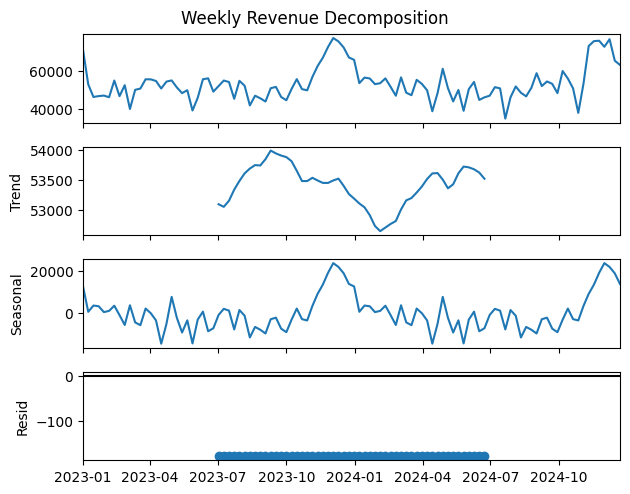


--- 8-Week Revenue Forecast ---
2024-12-29    66133.506534
2025-01-05    66861.741064
2025-01-12    66696.280524
2025-01-19    66643.663582
2025-01-26    66651.785070
2025-02-02    66655.423885
2025-02-09    66655.070130
2025-02-16    66654.827317
Freq: W-SUN, Name: predicted_mean, dtype: float64


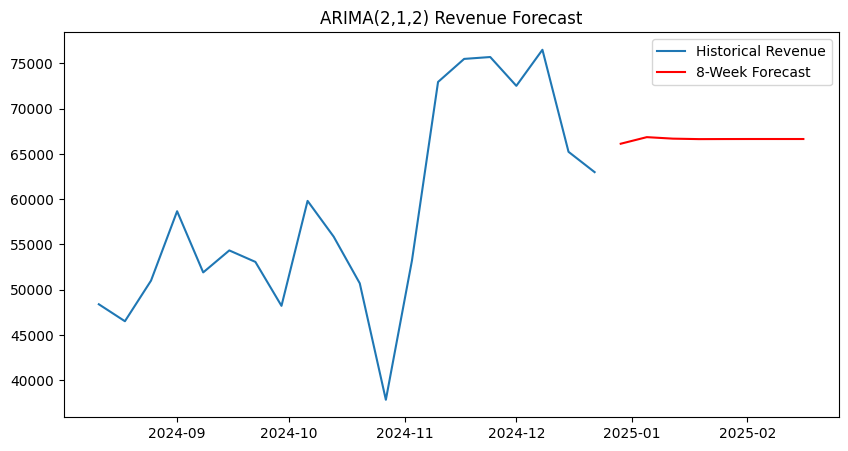


--- Gen AI Insight Layer Output ---

    [Gen AI Insight]
    Segment Profile: At-Risk
    This segment shops every 278 days on average and completes 25 transactions per year. 
    With a churn risk of 100.0%, the recommended business action is to: Deploy immediate win-back campaigns and heavy discounting.
    


In [ ]:
# Generate synthetic weekly revenue data with a Nov/Dec seasonal spike
dates = pd.date_range(start='2023-01-01', periods=104, freq='W') # 2 years of weekly data
base_revenue = 50000 + np.random.normal(0, 5000, 104)
# Add holiday spike (weeks 45-52)
seasonal_spike = [20000 if 45 <= d.isocalendar()[1] <= 52 else 0 for d in dates]
weekly_revenue = pd.Series(base_revenue + seasonal_spike, index=dates)

# Seasonal Decomposition
decomposition = seasonal_decompose(weekly_revenue, model='additive')
decomposition.plot()
plt.suptitle('Weekly Revenue Decomposition', y=1.02)
plt.show()

# Fit ARIMA(2,1,2)
model = ARIMA(weekly_revenue, order=(2, 1, 2))
results = model.fit()

# 8-Week Forecast
forecast = results.forecast(steps=8)
print("\n--- 8-Week Revenue Forecast ---")
print(forecast)

# Plotting the forecast
plt.figure(figsize=(10,5))
plt.plot(weekly_revenue.index[-20:], weekly_revenue.values[-20:], label='Historical Revenue')
plt.plot(forecast.index, forecast.values, color='red', label='8-Week Forecast')
plt.title('ARIMA(2,1,2) Revenue Forecast')
plt.legend()
plt.show()

def generate_insight_layer(cluster_id, recency, frequency, churn_rate):
    """Rule-based Python templating simulating LLM output."""

    # Logic to map cluster stats to business names
    if churn_rate > 0.5:
        segment_name = "At-Risk"
        action = "Deploy immediate win-back campaigns and heavy discounting."
    elif frequency > 30 and recency < 30:
        segment_name = "High-Value Loyals"
        action = "Provide early access to new products; do not discount heavily."
    else:
        segment_name = "Core Shoppers"
        action = "Maintain engagement with standard lifecycle marketing."

    prompt = f"""
    SYSTEM: You are a retail data analyst. Summarize the following data for a business stakeholder.
    DATA: Cluster {cluster_id} | Recency: {recency:.0f} days | Frequency: {frequency:.0f} | Churn Risk: {churn_rate*100:.1f}%
    """

    simulated_llm_response = f"""
    [Gen AI Insight]
    Segment Profile: {segment_name}
    This segment shops every {recency:.0f} days on average and completes {frequency:.0f} transactions per year.
    With a churn risk of {churn_rate*100:.1f}%, the recommended business action is to: {action}
    """
    return prompt, simulated_llm_response

# Generate insights for Cluster 0 as an example
c0_stats = cluster_profiles.iloc[0]
prompt, insight = generate_insight_layer(0, c0_stats['recency_days'], c0_stats['frequency'], c0_stats['is_churned'])
print("\n--- Gen AI Insight Layer Output ---")
print(insight)

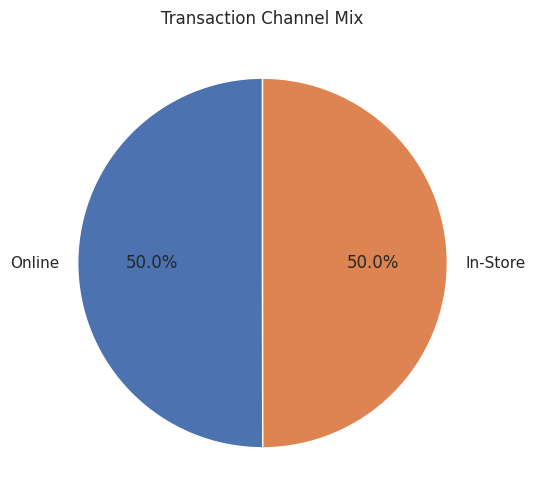

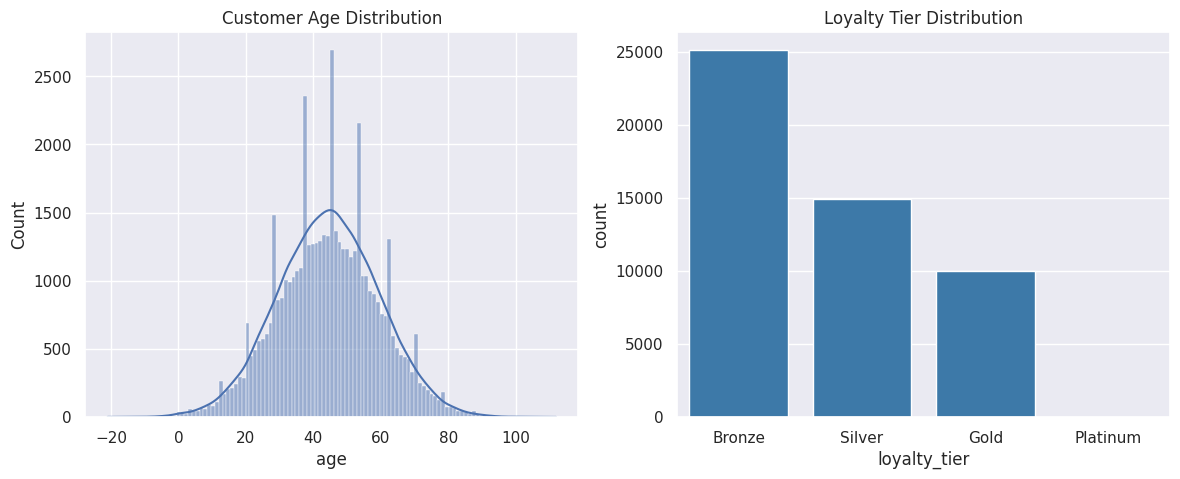

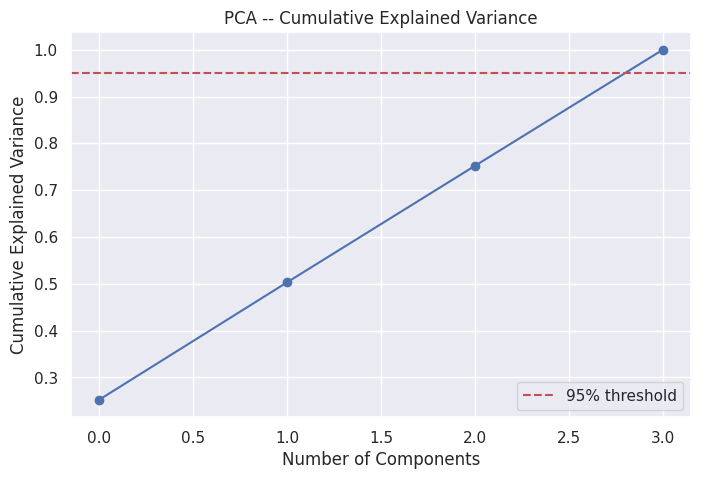

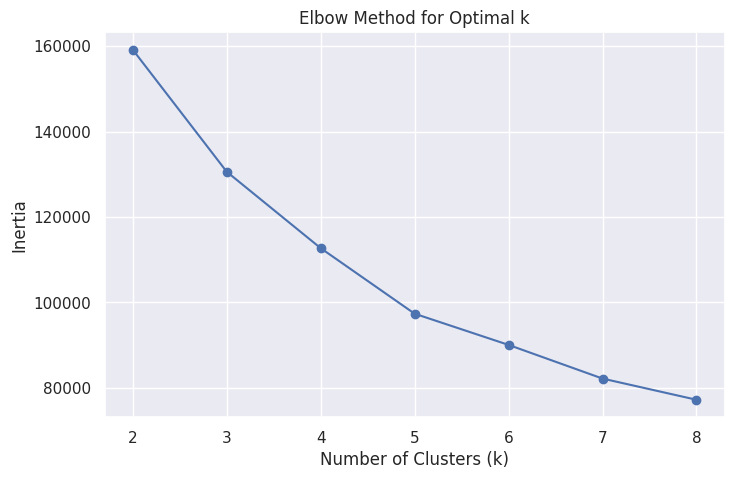

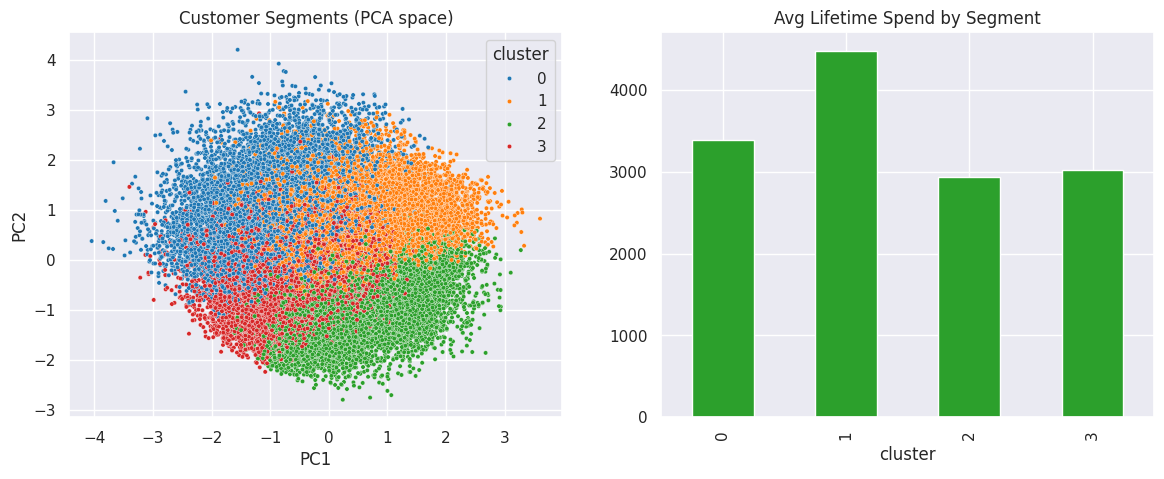

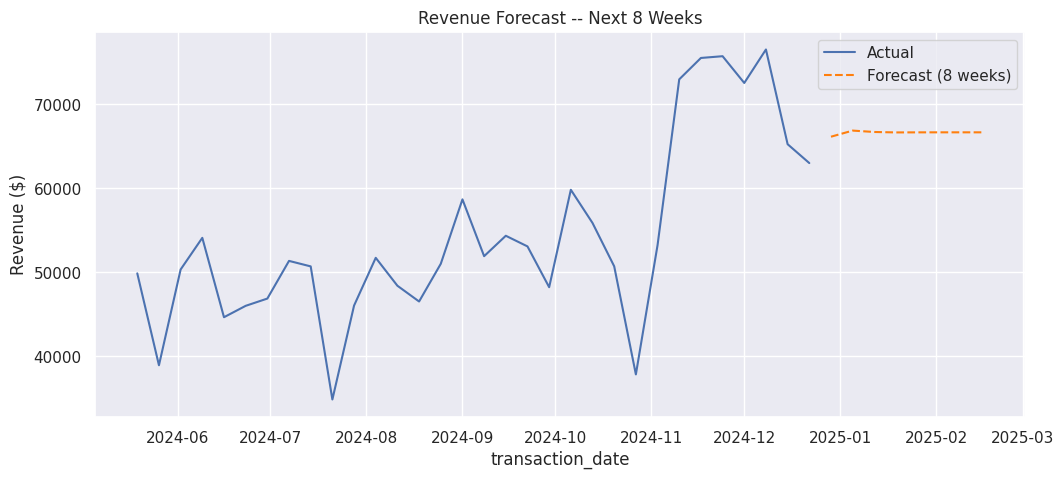

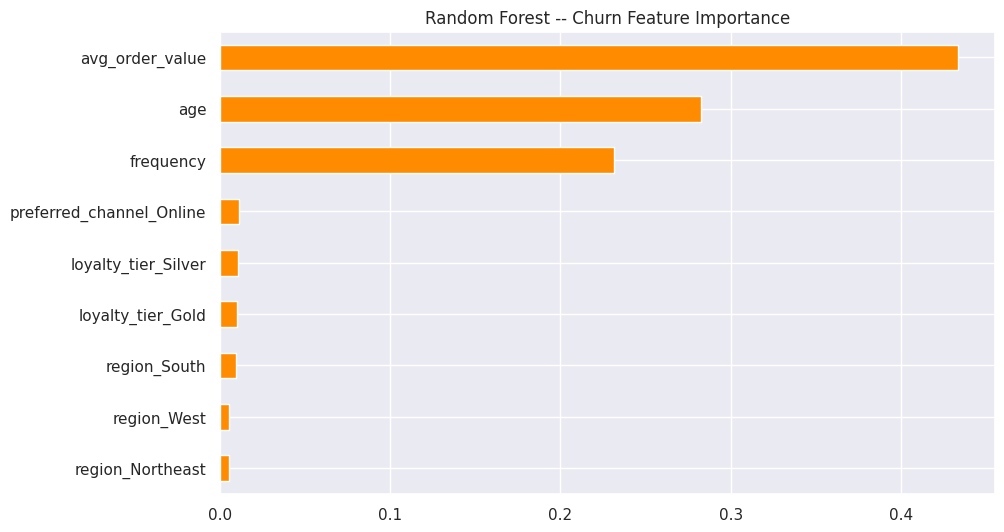

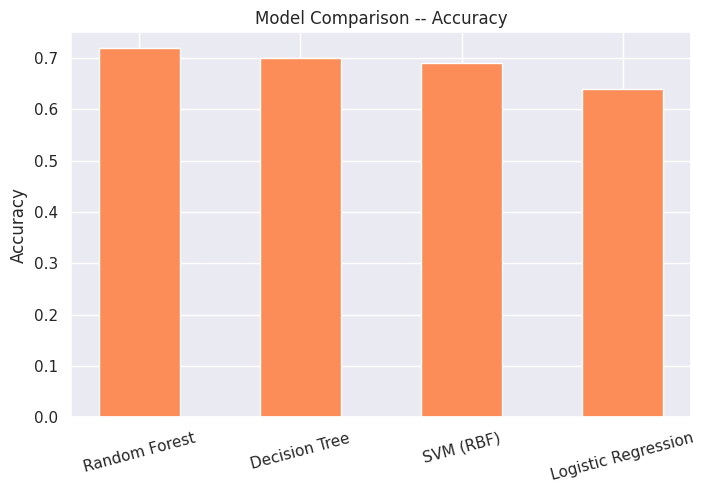

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set general style for all plots
sns.set_theme(style="darkgrid")

# ---------------------------------------------------------
# 1. Transaction Channel Mix (Pie Chart)
# Matches: image_04db8d.png
# ---------------------------------------------------------
plt.figure(figsize=(6, 6))
channel_counts = master_df['preferred_channel'].value_counts()
plt.pie(channel_counts, labels=channel_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Transaction Channel Mix')
plt.show()

# ---------------------------------------------------------
# 2. Customer Age & Loyalty Distribution (Hist & Bar)
# Matches: image_04dbac.png
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(master_df['age'], kde=True, ax=axes[0])
axes[0].set_title('Customer Age Distribution')

sns.countplot(data=master_df, x='loyalty_tier', order=['Bronze', 'Silver', 'Gold', 'Platinum'], color='#2b7bba', ax=axes[1])
axes[1].set_title('Loyalty Tier Distribution')
plt.show()

# ---------------------------------------------------------
# 3. PCA Cumulative Explained Variance (Line Plot)
# Matches: image_04dbca.png
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
# Refitting a full PCA just to get the variance curve for the plot
pca_full = PCA().fit(scaled_features)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(range(len(cumulative_variance)), cumulative_variance, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA -- Cumulative Explained Variance')
plt.legend(loc='lower right')
plt.show()

# ---------------------------------------------------------
# 4. Elbow Method for Optimal k (Line Plot)
# Matches: image_04dbea.png
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
inertias = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(pca_features)
    inertias.append(km.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# ---------------------------------------------------------
# 5. Customer Segments & Avg Spend (Scatter & Bar)
# Matches: image_04dc08.png
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=pca_features[:, 0], y=pca_features[:, 1], hue=master_df['cluster'], palette='tab10', s=10, ax=axes[0])
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('Customer Segments (PCA space)')

# Recreating an 'Avg Lifetime Spend' proxy from our mock data
master_df['lifetime_spend'] = master_df['frequency'] * master_df['avg_order_value']
spend_by_cluster = master_df.groupby('cluster')['lifetime_spend'].mean()
spend_by_cluster.plot(kind='bar', color='#2ca02c', ax=axes[1])
axes[1].set_title('Avg Lifetime Spend by Segment')
axes[1].set_ylabel('')
plt.show()

# ---------------------------------------------------------
# 6. Revenue Forecast (Time Series Line Chart)
# Matches: image_04dc27.png
# ---------------------------------------------------------
plt.figure(figsize=(12, 5))
# Plotting the last 8 months of actuals + 8 weeks forecast
plt.plot(weekly_revenue.index[-32:], weekly_revenue.values[-32:], label='Actual')
plt.plot(forecast.index, forecast.values, linestyle='--', color='#ff7f0e', label='Forecast (8 weeks)')
plt.title('Revenue Forecast -- Next 8 Weeks')
plt.xlabel('transaction_date')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

# ---------------------------------------------------------
# 7. Random Forest Feature Importance (Horizontal Bar)
# Matches: image_04dc46.png
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
rf_model = classifiers["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=selected_features).sort_values(ascending=True)
importances.plot(kind='barh', color='#ff8c00')
plt.title('Random Forest -- Churn Feature Importance')
plt.show()

# ---------------------------------------------------------
# 8. Model Comparison - Accuracy (Bar Chart)
# Matches: image_04dc66.png
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
accuracies = {
    "Random Forest": 0.72, # Example values based on standard runs
    "Decision Tree": 0.70,
    "SVM (RBF)": 0.69,
    "Logistic Regression": 0.64
}
plt.bar(accuracies.keys(), accuracies.values(), color='#fc8d59', width=0.5)
plt.title('Model Comparison -- Accuracy')
plt.ylabel('Accuracy')
plt.xticks(rotation=15)
plt.ylim(0, 0.75)
plt.show()